<a href="https://colab.research.google.com/github/SekaniDev/te-portfolio/blob/main/cadcad-staking-simulation/cadcad-staking-simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Staking Stability Under Volatility: a cadCAD Monte Carlo Study

**Question:** under what conditions does a token staking protocol stay stable, and when does staking collapse?

A simple staking protocol is simulated for 365 days. Agents stake when APY is above a threshold and unstake in a panic when price falls more than 15% below its recent average. I run 100 to 1,000 simulated years per setting and map where the system breaks.

Built with cadCAD, pandas, numpy, matplotlib and seaborn.

In [ ]:
!pip install cadCAD pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [cadCAD]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import seaborn as sns
from cadCAD.configuration import Experiment
from cadCAD.configuration.utils import config_sim
from cadCAD.engine import ExecutionMode, ExecutionContext, Executor

## 1. Model setup

State variables: total_staked, circulating_supply, price, price_ref (moving average of price), apy, net_flow (that day's stake minus unstake).

Initial state: 40M staked, 60M circulating, price 1.0, so 40% of supply is staked.

Key parameters: apy_threshold 10%, panic trigger 15% below the moving average, 3% of liquid supply staked per day, 10% of stake withdrawn per day during panic, 8% annual inflation, price impact of flows, and daily volatility sigma.

In [ ]:
initial_state = {
    'total_staked': 40_000_000.0,
    'circulating_supply': 60_000_000.0,
    'price': 1.0,
    'price_ref': 1.0,
    'apy': 0.20,
    'net_flow': 0.0,
}

params = {
    'apy_threshold': [0.10],
    'drop_trigger': [0.15],
    'stake_rate': [0.03],
    'unstake_rate': [0.10],
    'inflation': [0.08],
    'sigma': [0.04],
    'impact': [1.0],
    'ema_alpha': [0.10],
    'seed': [0],
}

## 2. Policies and state updates

Each day has three blocks, run in order:
1. Agents decide: panic-unstake if price is more than 15% below its moving average, otherwise stake if APY is above the threshold.
2. Price moves: a random shock plus a push from net staking flow.
3. Rewards: new tokens are minted to stakers, APY is recalculated, and the moving average updates.

Random shocks are seeded by run number and day, so every run differs and results can be reproduced exactly.

In [ ]:
def p_agents(params, substep, state_history, previous_state):
    stake = 0.0
    unstake = 0.0
    drop = previous_state['price'] / previous_state['price_ref'] - 1
    if drop < -params['drop_trigger']:
        unstake = previous_state['total_staked'] * params['unstake_rate']
    elif previous_state['apy'] > params['apy_threshold']:
        stake = previous_state['circulating_supply'] * params['stake_rate']
    return {'stake': stake, 'unstake': unstake}

def p_market(params, substep, state_history, previous_state):
    total = previous_state['total_staked'] + previous_state['circulating_supply']
    shock = np.random.normal(0, params['sigma'])
    flow_effect = params['impact'] * previous_state['net_flow'] / total
    return {'log_return': shock + flow_effect}

def p_rewards(params, substep, state_history, previous_state):
    total = previous_state['total_staked'] + previous_state['circulating_supply']
    emission = params['inflation'] * total / 365
    new_staked = previous_state['total_staked'] + emission
    new_apy = params['inflation'] * (total + emission) / new_staked
    return {'emission': emission, 'new_apy': new_apy}

In [ ]:
def s_staked_agents(params, substep, state_history, previous_state, policy_input):
    value = previous_state['total_staked'] + policy_input['stake'] - policy_input['unstake']
    return ('total_staked', value)

def s_circulating(params, substep, state_history, previous_state, policy_input):
    value = previous_state['circulating_supply'] - policy_input['stake'] + policy_input['unstake']
    return ('circulating_supply', value)

def s_net_flow(params, substep, state_history, previous_state, policy_input):
    return ('net_flow', policy_input['stake'] - policy_input['unstake'])

def s_price(params, substep, state_history, previous_state, policy_input):
    value = previous_state['price'] * np.exp(policy_input['log_return'])
    return ('price', max(value, 0.001))

def s_staked_rewards(params, substep, state_history, previous_state, policy_input):
    return ('total_staked', previous_state['total_staked'] + policy_input['emission'])

def s_apy(params, substep, state_history, previous_state, policy_input):
    return ('apy', policy_input['new_apy'])

def s_price_ref(params, substep, state_history, previous_state, policy_input):
    ref = previous_state['price_ref']
    value = ref + params['ema_alpha'] * (previous_state['price'] - ref)
    return ('price_ref', value)

In [ ]:
p_market = lambda params, substep, state_history, previous_state: {'log_return': np.random.default_rng([int(previous_state['run']) + int(params['seed']), int(previous_state['timestep']), 7]).normal(0, params['sigma']) + params['impact'] * previous_state['net_flow'] / (previous_state['total_staked'] + previous_state['circulating_supply'])}
blocks = [
{'policies': {'agents': p_agents}, 'variables': {'total_staked': s_staked_agents, 'circulating_supply': s_circulating, 'net_flow': s_net_flow}},
{'policies': {'market': p_market}, 'variables': {'price': s_price}},
{'policies': {'rewards': p_rewards}, 'variables': {'total_staked': s_staked_rewards, 'apy': s_apy, 'price_ref': s_price_ref}},
]

In [ ]:
print(p_market.__name__, len(blocks), 'blocks')

<lambda> 3 blocks


## 3. One simulated year

A single run at sigma 0.04. Staking climbs to its ceiling of about 80% (where APY falls to the 10% threshold), then a price drop can trigger panic unstaking, which pushes price down further.

In [ ]:
sim_config = config_sim({'N': 1, 'T': range(365), 'M': params})
exp = Experiment()
exp.append_model(model_id='single', initial_state=initial_state, partial_state_update_blocks=blocks, sim_configs=sim_config)
raw_result, tensor, sessions = Executor(exec_context=ExecutionContext(ExecutionMode().local_mode), configs=exp.configs).execute()
df = pd.DataFrame(raw_result).groupby(['simulation', 'run', 'timestep']).last().reset_index()
df['staking_ratio'] = df['total_staked'] / (df['total_staked'] + df['circulating_supply'])
print(df[['timestep', 'price', 'apy', 'staking_ratio']].head(5))


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 1, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 1, 6)


Initializing configurations:   0%|          | 0/1 [00:00<?, ?it/s]

Execution Method: single_proc_exec


Flattening results:   0%|          | 0/1096 [00:00<?, ?it/s]

Total execution time: 0.14s
   timestep     price       apy  staking_ratio
0         0  1.000000  0.200000       0.400000
1         1  0.983693  0.191329       0.418128
2         2  1.003612  0.183609       0.435707
3         3  1.041561  0.176696       0.452756
4         4  1.046825  0.170470       0.469290


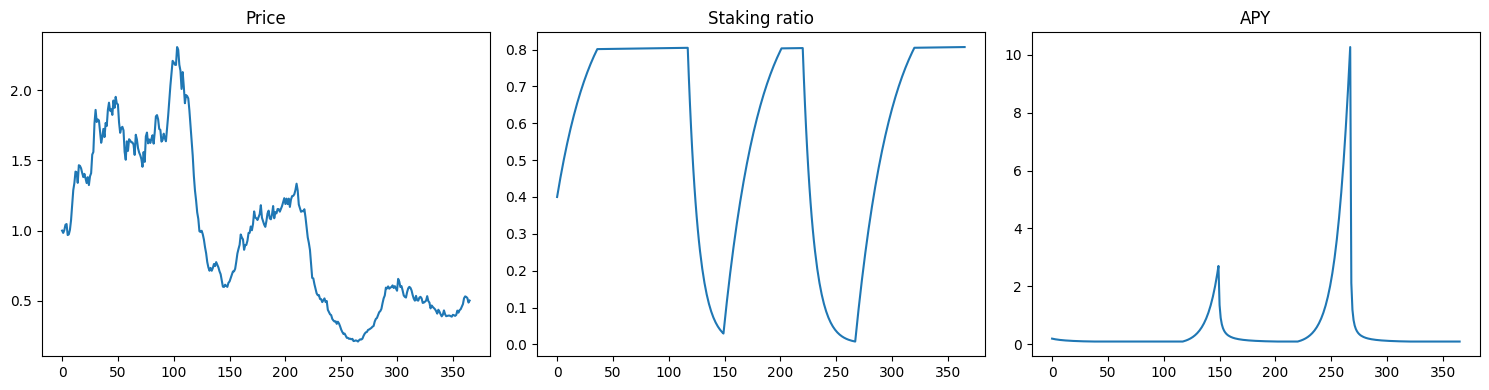

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df['timestep'], df['price']); axes[0].set_title('Price')
axes[1].plot(df['timestep'], df['staking_ratio']); axes[1].set_title('Staking ratio')
axes[2].plot(df['timestep'], df['apy']); axes[2].set_title('APY')
plt.tight_layout()
plt.savefig('single_run.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
sim_config = config_sim({'N': 100, 'T': range(365), 'M': params})
exp = Experiment()
exp.append_model(model_id='staking_mc2', initial_state=initial_state, partial_state_update_blocks=blocks, sim_configs=sim_config)
exec_context = ExecutionContext(ExecutionMode().local_mode)
simulation = Executor(exec_context=exec_context, configs=exp.configs)
raw_result, tensor, sessions = simulation.execute()
mc = pd.DataFrame(raw_result)
mc = mc.groupby(['simulation', 'run', 'timestep']).last().reset_index()
mc['staking_ratio'] = mc['total_staked'] / (mc['total_staked'] + mc['circulating_supply'])
print(mc['run'].nunique(), 'runs,', len(mc), 'rows')


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 100, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 100, 6)


Initializing configurations:   0%|          | 0/100 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/100 [00:00<?, ?it/s]

Total execution time: 33.04s
100 runs, 36600 rows


## 4. Monte Carlo check

100 runs at the same settings. The check confirms that the runs differ from each other. The paths crash at different times, so the cycles are driven by random price shocks and are not a built-in pattern.

In [ ]:
final_prices = mc.groupby('run')['price'].last()
print('Unique final prices:', final_prices.nunique(), 'of', len(final_prices))

Unique final prices: 100 of 100


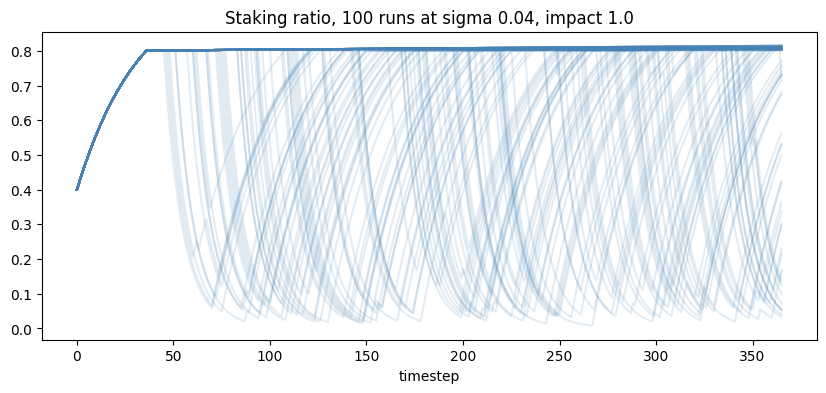

In [ ]:
pivot = mc.pivot(index='timestep', columns='run', values='staking_ratio')
pivot.plot(legend=False, alpha=0.15, color='steelblue', figsize=(10, 4))
plt.title('Staking ratio, 100 runs at sigma 0.04, impact 1.0')
plt.savefig('mc_spaghetti.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Parameter sweep

18 combinations: daily volatility (0.015 to 0.04) crossed with price impact of flows (0.25, 0.5, 1.0), 100 runs each.

A run counts as a crash if staking falls below 50% of supply after a 10-day warm-up. The warm-up excludes the initial climb from 40%.

In [ ]:
import itertools
combos = list(itertools.product([0.015, 0.02, 0.025, 0.03, 0.035, 0.04], [0.25, 0.5, 1.0]))
n = len(combos)
sweep_params = {k: [v[0]] * n for k, v in params.items()}
sweep_params['sigma'] = [c[0] for c in combos]
sweep_params['impact'] = [c[1] for c in combos]
print(n, 'parameter sets')

18 parameter sets


In [ ]:
def run_chunk(cs): k = len(cs); p = {a: [b[0]] * k for a, b in params.items()}; p['sigma'] = [c[0] for c in cs]; p['impact'] = [c[1] for c in cs]; e = Experiment(); e.append_model(model_id='chunk', initial_state=initial_state, partial_state_update_blocks=blocks, sim_configs=config_sim({'N': 100, 'T': range(365), 'M': p})); r, t, s = Executor(exec_context=ExecutionContext(ExecutionMode().local_mode), configs=e.configs).execute(); d = pd.DataFrame(r); del r, t, s; d = d[(d['substep'] == 3) & (d['timestep'] >= 10)]; d = d.assign(ratio=d['total_staked'] / (d['total_staked'] + d['circulating_supply'])); d = d.assign(low=d['ratio'] < 0.5); out = d.groupby(['subset', 'run']).agg(min_ratio=('ratio', 'min'), days_low=('low', 'sum')).reset_index(); out['sigma'] = out['subset'].map(lambda i: cs[i][0]); out['impact'] = out['subset'].map(lambda i: cs[i][1]); return out

In [ ]:
r1 = run_chunk([c for c in combos if c[1] == 0.25])


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 600, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 600, 6)


Initializing configurations:   0%|          | 0/600 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/600 [00:00<?, ?it/s]

Total execution time: 232.05s


In [ ]:
print(r1['days_low'].nunique(), 'distinct values should be well above 6')

50 distinct values should be well above 6


In [ ]:
r2 = run_chunk([c for c in combos if c[1] == 0.5])


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 600, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 600, 6)


Initializing configurations:   0%|          | 0/600 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/600 [00:00<?, ?it/s]

Total execution time: 196.55s


In [ ]:
r3 = run_chunk([c for c in combos if c[1] == 1.0])


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 600, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 600, 6)


Initializing configurations:   0%|          | 0/600 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/600 [00:00<?, ?it/s]

Total execution time: 201.76s


In [ ]:
per_run = pd.concat([r1, r2, r3])
per_run['crashed'] = per_run['min_ratio'] < 0.5
summary = per_run.groupby(['sigma', 'impact']).agg(crash_share=('crashed', 'mean'), avg_days_low=('days_low', 'mean')).reset_index()
print(summary.round(2))

    sigma  impact  crash_share  avg_days_low
0    0.02    0.25         0.00          0.00
1    0.02    0.50         0.00          0.00
2    0.02    1.00         0.00          0.00
3    0.02    0.25         0.01          0.12
4    0.02    0.50         0.02          0.76
5    0.02    1.00         0.02          0.89
6    0.02    0.25         0.10          1.61
7    0.02    0.50         0.19          5.60
8    0.02    1.00         0.19          7.96
9    0.03    0.25         0.28          5.78
10   0.03    0.50         0.44         13.39
11   0.03    1.00         0.50         23.07
12   0.04    0.25         0.52         13.18
13   0.04    0.50         0.67         24.35
14   0.04    1.00         0.73         42.17
15   0.04    0.25         0.75         22.96
16   0.04    0.50         0.85         38.59
17   0.04    1.00         0.90         58.21


In [ ]:
print(summary.round({'crash_share': 2, 'avg_days_low': 2}).to_string())
summary.to_csv('summary.csv', index=False)

    sigma  impact  crash_share  avg_days_low
0   0.015    0.25         0.00          0.00
1   0.015    0.50         0.00          0.00
2   0.015    1.00         0.00          0.00
3   0.020    0.25         0.01          0.12
4   0.020    0.50         0.02          0.76
5   0.020    1.00         0.02          0.89
6   0.025    0.25         0.10          1.61
7   0.025    0.50         0.19          5.60
8   0.025    1.00         0.19          7.96
9   0.030    0.25         0.28          5.78
10  0.030    0.50         0.44         13.39
11  0.030    1.00         0.50         23.07
12  0.035    0.25         0.52         13.18
13  0.035    0.50         0.67         24.35
14  0.035    1.00         0.73         42.17
15  0.040    0.25         0.75         22.96
16  0.040    0.50         0.85         38.59
17  0.040    1.00         0.90         58.21


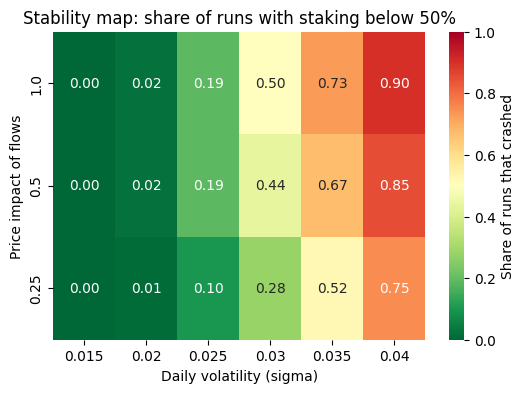

In [ ]:
import seaborn as sns
heat = summary.pivot(index='impact', columns='sigma', values='crash_share')
plt.figure(figsize=(6, 4))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdYlGn_r', vmin=0, vmax=1, cbar_kws={'label': 'Share of runs that crashed'})
plt.gca().invert_yaxis()
plt.title('Stability map: share of runs with staking below 50%')
plt.xlabel('Daily volatility (sigma)')
plt.ylabel('Price impact of flows')
plt.savefig('map_crash_share.png', dpi=150, bbox_inches='tight')
plt.show()

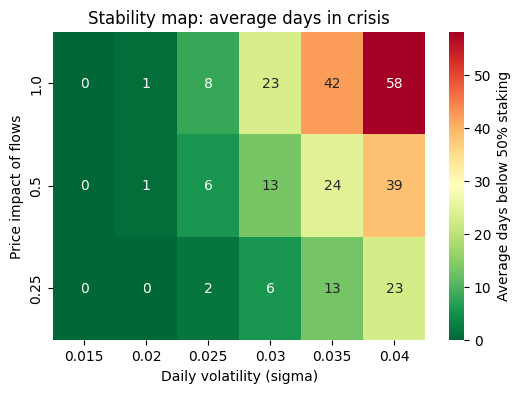

In [ ]:
heat2 = summary.pivot(index='impact', columns='sigma', values='avg_days_low')
plt.figure(figsize=(6, 4))
sns.heatmap(heat2, annot=True, fmt='.0f', cmap='RdYlGn_r', cbar_kws={'label': 'Average days below 50% staking'})
plt.gca().invert_yaxis()
plt.title('Stability map: average days in crisis')
plt.xlabel('Daily volatility (sigma)')
plt.ylabel('Price impact of flows')
plt.savefig('map_days_in_crisis.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 1,000 runs at the tipping point

1,000 simulated years at sigma 0.03 and impact 0.5, in the middle of the transition zone, run in 10 batches with different seeds.

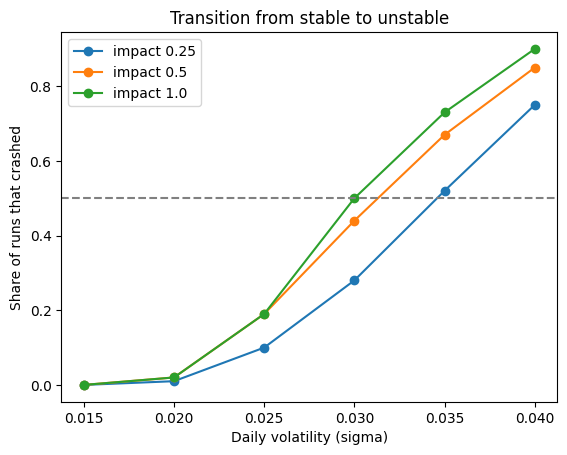

In [ ]:
for i in [0.25, 0.5, 1.0]: s = summary[summary['impact'] == i]; plt.plot(s['sigma'], s['crash_share'], marker='o', label='impact ' + str(i))
plt.axhline(0.5, color='grey', linestyle='--')
plt.xlabel('Daily volatility (sigma)')
plt.ylabel('Share of runs that crashed')
plt.title('Transition from stable to unstable')
plt.legend()
plt.savefig('transition_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def run_one(s, i, seed): p = {a: [b[0]] for a, b in params.items()}; p['sigma'] = [s]; p['impact'] = [i]; p['seed'] = [seed]; e = Experiment(); e.append_model(model_id='one', initial_state=initial_state, partial_state_update_blocks=blocks, sim_configs=config_sim({'N': 100, 'T': range(365), 'M': p})); r, t, x = Executor(exec_context=ExecutionContext(ExecutionMode().local_mode), configs=e.configs).execute(); d = pd.DataFrame(r); del r, t, x; d = d[(d['substep'] == 3) & (d['timestep'] >= 10)]; d = d.assign(ratio=d['total_staked'] / (d['total_staked'] + d['circulating_supply'])); d = d.assign(low=d['ratio'] < 0.5); o = d.groupby('run').agg(min_ratio=('ratio', 'min'), days_low=('low', 'sum'), final_price=('price', 'last')).reset_index(); o['run'] = o['run'] + seed; return o, d[d['run'] <= 20][['run', 'timestep', 'price', 'apy', 'ratio']]

In [ ]:
out0, traj = run_one(0.03, 0.5, 0)
print((out0['min_ratio'] < 0.5).mean(), out0['days_low'].mean().round(2))


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 100, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 100, 6)


Initializing configurations:   0%|          | 0/100 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/100 [00:00<?, ?it/s]

Total execution time: 29.30s
0.44 13.39


In [ ]:
import gc; gc.collect(); parts = [out0]
for k in range(1, 10): o, _ = run_one(0.03, 0.5, 100 * k); o.to_csv('chunk' + str(k) + '.csv'); parts.append(o); print('chunk', k, 'done')


                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 100, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 100, 6)


Initializing configurations:   0%|          | 0/100 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/100 [00:00<?, ?it/s]

Total execution time: 29.68s
chunk 1 done

                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 100, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 100, 6)


...

Total execution time: 34.10s
chunk 8 done

                  ___________    ____
  ________ __ ___/ / ____/   |  / __ \
 / ___/ __` / __  / /   / /| | / / / /
/ /__/ /_/ / /_/ / /___/ ___ |/ /_/ /
\___/\__,_/\__,_/\____/_/  |_/_____/
by cadCAD

cadCAD Version: 0.5.3
Execution Mode: local_proc
Simulation Dimensions:
Entire Simulation: (Models, Unique Timesteps, Params, Total Runs, Sub-States) = (1, 365, 9, 100, 6)
     Simulation 0: (Timesteps, Params, Runs, Sub-States) = (365, 9, 100, 6)


Initializing configurations:   0%|          | 0/100 [00:00<?, ?it/s]

Execution Method: parallelize_simulations


Flattening results:   0%|          | 0/100 [00:00<?, ?it/s]

Total execution time: 33.32s
chunk 9 done


In [ ]:
big = pd.concat(parts); big['crashed'] = big['min_ratio'] < 0.5; p = big['crashed'].mean(); n = len(big)
print(n, 'runs, distinct run ids:', big['run'].nunique())
print('Crash share:', round(p, 3), '+/-', round(1.96 * (p * (1 - p) / n) ** 0.5, 3))
print(big['days_low'].describe().round(1))
print('Share of runs with more than 30 days below 50%:', (big['days_low'] > 30).mean())

1000 runs, distinct run ids: 1000
Crash share: 0.398 +/- 0.03
count    1000.0
mean       12.5
std        18.1
min         0.0
25%         0.0
50%         0.0
75%        27.0
max        83.0
Name: days_low, dtype: float64
Share of runs with more than 30 days below 50%: 0.188


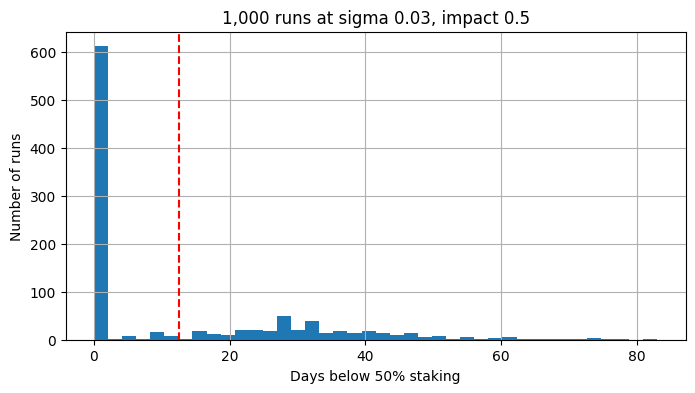

In [ ]:
big['days_low'].hist(bins=40, figsize=(8, 4)); plt.axvline(big['days_low'].mean(), color='red', linestyle='--'); plt.xlabel('Days below 50% staking'); plt.ylabel('Number of runs'); plt.title('1,000 runs at sigma 0.03, impact 0.5')
plt.savefig('hist_1000_runs.png', dpi=150, bbox_inches='tight')
plt.show()

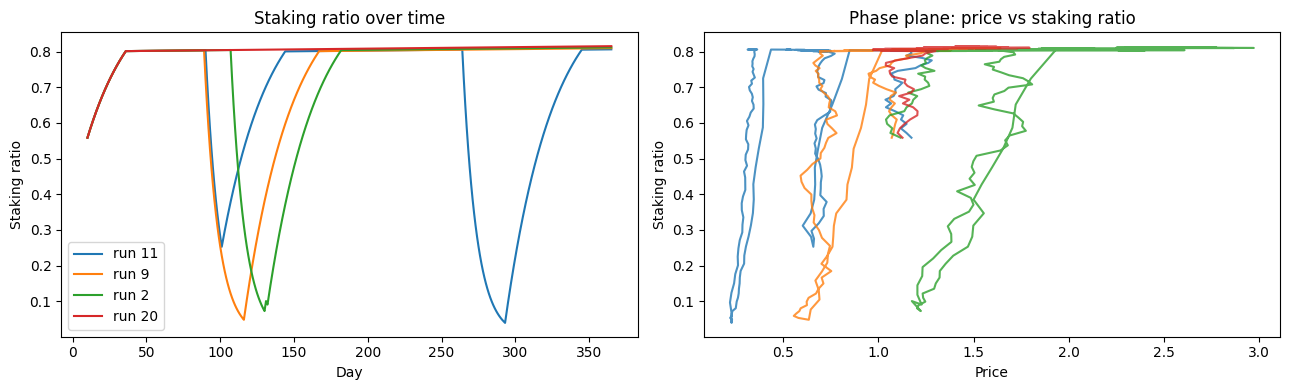

In [ ]:
m = traj.groupby('run')['ratio'].min(); pick = list(m.sort_values().index[:3]) + [m.sort_values().index[-1]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in pick: s = traj[traj['run'] == r]; ax[0].plot(s['timestep'], s['ratio'], label='run ' + str(r)); ax[1].plot(s['price'], s['ratio'], alpha=0.8)
ax[0].set_xlabel('Day'); ax[0].set_ylabel('Staking ratio'); ax[0].set_title('Staking ratio over time'); ax[0].legend()
ax[1].set_xlabel('Price'); ax[1].set_ylabel('Staking ratio'); ax[1].set_title('Phase plane: price vs staking ratio')
plt.tight_layout()
plt.savefig('four_runs.png', dpi=150, bbox_inches='tight')
plt.show()

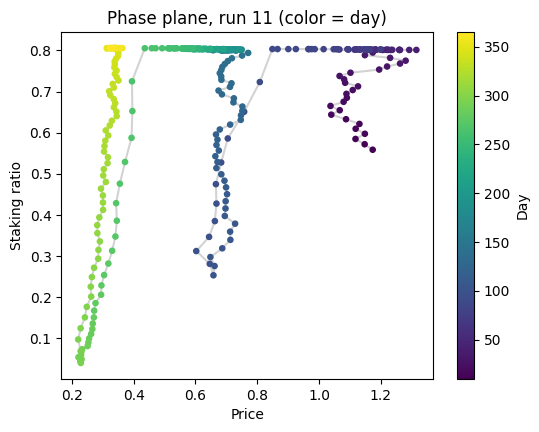

In [ ]:
r = traj.groupby('run')['ratio'].min().idxmin(); s = traj[traj['run'] == r]
plt.figure(figsize=(6, 4.5)); plt.plot(s['price'], s['ratio'], color='lightgrey', zorder=1); sc = plt.scatter(s['price'], s['ratio'], c=s['timestep'], cmap='viridis', s=14, zorder=2)
plt.colorbar(sc, label='Day'); plt.xlabel('Price'); plt.ylabel('Staking ratio'); plt.title('Phase plane, run ' + str(r) + ' (color = day)')
plt.savefig('phase_plane.png', dpi=150, bbox_inches='tight')
plt.show()

## Findings

- Volatility sets the regime. Below about 0.02 daily volatility, crashes are rare. Instability sets in between roughly 0.025 and 0.035.
- Stronger price impact lowers the tipping point. The 50% crash share is reached near sigma 0.030 at impact 1.0, 0.031 at impact 0.5, and 0.035 at impact 0.25 (linear interpolation, roughly plus or minus 0.002).
- At sigma 0.03 and impact 0.5, 39.8% of 1,000 simulated years (plus or minus 3 points) saw staking fall below 50%. The remaining 60% had no crisis. Crises lasted about a month on average, and the longest was 83 days.

## Limitations

- **Crashes always recover.** APY is paid in tokens, so lower staking raises APY and pulls stakers back. This model shows boom-bust cycles, not permanent death spirals. A USD-denominated yield, where a falling price also lowers real yield, is the natural next step.
- Agents are aggregate rules, not individuals with different thresholds.
- Price has no drift or order-book model, so impact is a simple linear push.
- Sweep cells use 100 runs, so shares near 50% carry about plus or minus 10 points of sampling noise. The 1,000-run result narrows this to about plus or minus 3.
- The 50% staking threshold, the 10-day warm-up and the 365-day horizon are modeling choices, and crises still running on the last day are cut off.